In [182]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress

from scipy.io import loadmat
import h5py


## **Data Loading**

In [204]:
data = loadmat("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_FRINT_Fit/Comportement_FRINT_ENS_num5_LL1311_M5_VBMC")
out = data["out_vbmc"][0,0]

In [205]:
filepaths = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_FRINT_Fit/*M5*VBMC.mat")
outs = [loadmat(f)["out_vbmc"][0,0] for f in filepaths]

## **Exploring Dataset Matlab**

In [206]:
print(out.dtype.names)

('s_sen', 'g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 's_fac', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep', 'p_lap', 'pnam', 'pmap', 'pavg', 'fitalgo', 'version', 'tfit', 'nsmp', 'nres', 'nobs', 'nfit', 'vp', 'elbo', 'elbo_sd', 'xnam', 'xmap', 'xavg', 'xstd', 'xcov', 'xmed', 'xqrt', 'xc95', 'xnam_all', 'xhat_all', 'options', 'output', 'tss', 'ess', 'zang_f', 'zabs_f', 'xcon_f', 'zang_u', 'zabs_u', 'xcon_u')


In [207]:
# to get the name of a parameter :
print([str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()])

# to get the value of a parameter :
print(out["xavg"].squeeze())

# to get one item from the file : 
print(out["g_sen"].item())

# to get the list of items of a parameter : 
print(out["pmap"][0].item())

['g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep']
[ 1.00994195  0.48299202  0.1472296  -0.57869694  0.77457611  0.84202605
  0.57207059  0.7689688   0.14214459]
1.0099419456461458
(array([[0]], dtype=uint8), array([[0.98453029]]), array([[0.48638325]]), array([[0.11800041]]), array([[-0.57526005]]), array([[0]], dtype=uint8), array([[0.66121676]]), array([[0.75842828]]), array([[0.51260302]]), array([[0.73041806]]), array([[0.14322807]]), array([[0]], dtype=uint8))


## **Info and Dataframes**

In [208]:
tfit = out["tfit"][0].item()
print("total fitting time =", tfit)
nfit = out["nfit"][0].item()
print("number of fitted parameters =", nfit)
xnam = out["xnam"][0]
print("the name of fitted parameters are :", [str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()])

total fitting time = 494.84331504166664
number of fitted parameters = 9
the name of fitted parameters are : ['g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep']


In [209]:
parameters = pd.DataFrame(index= [str(x[0]) if len(x) > 0 else "" for x in out["pnam"].squeeze()], columns =  ["value"])
for column, num in zip([str(x[0]) if len(x) > 0 else "" for x in out["pnam"].squeeze()], range(12)) : 
    parameters.loc[column] = out[num].item()

parameters["mod"] = np.squeeze(out["pmap"][0].item())
parameters["average"] = np.squeeze(out["pavg"][0].item())

parameters


,value,mod,average
s_sen,0,0.000000,0.000000
g_sen,1.009942,0.984530,1.009942
s_rot,0.482992,0.486383,0.482992
d_rot_p,0.14723,0.118000,0.147230
d_rot_m,-0.578697,-0.575260,-0.578697
s_fac,0,0.000000,0.000000
w_fac_p,0.774576,0.661217,0.774576
w_fac_m,0.842026,0.758428,0.842026
s_int,0.572071,0.512603,0.572071
l_int,0.768969,0.730418,0.768969


In [210]:
np.rad2deg(0.635651)

36.42011954327029

In [211]:
fitted_parameters = pd.DataFrame(index= [str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()], columns =  ["average", "mod", "std","median", "Q1", "Q3", "c95_left", "c95_right"])
for column, num in zip([str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()], range(12)) : 
    fitted_parameters["average"] = out["xavg"].squeeze()
    fitted_parameters["mod"] = out["xmap"].squeeze()
    fitted_parameters["std"] = out["xstd"].squeeze()
    fitted_parameters["median"] = out["xmed"].squeeze()
    fitted_parameters["Q1"] = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"] = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"] = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

fitted_parameters

,average,mod,std,median,Q1,Q3,c95_left,c95_right
g_sen,1.009942,0.984530,0.206463,1.011329,0.871316,1.149842,0.601987,1.411063
s_rot,0.482992,0.486383,0.042885,0.482983,0.454270,0.511489,0.398719,0.568141
d_rot_p,0.147230,0.118000,0.074938,0.145851,0.096590,0.196763,0.003176,0.297952
d_rot_m,-0.578697,-0.575260,0.094425,-0.580528,-0.643731,-0.516050,-0.757529,-0.388419
w_fac_p,0.774576,0.661217,0.230542,0.744660,0.609537,0.906791,0.411767,1.308175
w_fac_m,0.842026,0.758428,0.312829,0.797936,0.615138,1.021745,0.360808,1.571889
s_int,0.572071,0.512603,0.104400,0.562848,0.502200,0.630770,0.390610,0.811904
l_int,0.768969,0.730418,0.203574,0.753437,0.624514,0.896134,0.416324,1.211503
s_rep,0.142145,0.143228,0.043666,0.137245,0.111055,0.167723,0.071015,0.241946


## **for all subjects**

In [212]:
all_g_sen = None
all_s_rot = None
all_d_rot_p = None
all_d_rot_m = None
all_s_fac = None
all_w_fac_p = None
all_w_fac_m = None
all_s_rep = None
all_s_int = None
all_p_lap = None
all_l_int = None

for i, out in enumerate(outs):
    fitted_parameters = pd.DataFrame(
        index=[str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()],
        columns=["average", "mod", "std", "median", "Q1", "Q3", "c95_left", "c95_right"]
    )

    fitted_parameters["average"]   = out["xavg"].squeeze()
    fitted_parameters["mod"]       = out["xmap"].squeeze()
    fitted_parameters["std"]       = out["xstd"].squeeze()
    fitted_parameters["median"]    = out["xmed"].squeeze()
    fitted_parameters["Q1"]        = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"]        = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"]  = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

    row_g_sen   = fitted_parameters.loc[["g_sen"]].reset_index(drop=True)
    row_s_rot   = fitted_parameters.loc[["s_rot"]].reset_index(drop=True)
    row_d_rot_p = fitted_parameters.loc[["d_rot_p"]].reset_index(drop=True)
    row_d_rot_m = fitted_parameters.loc[["d_rot_m"]].reset_index(drop=True)
    row_w_fac_p = fitted_parameters.loc[["w_fac_p"]].reset_index(drop=True)
    row_w_fac_m = fitted_parameters.loc[["w_fac_m"]].reset_index(drop=True)
    row_s_rep   = fitted_parameters.loc[["s_rep"]].reset_index(drop=True)
    row_s_int   = fitted_parameters.loc[["s_int"]].reset_index(drop=True)
    row_l_int   = fitted_parameters.loc[["l_int"]].reset_index(drop=True)

    all_g_sen   = row_g_sen   if all_g_sen is None   else pd.concat([all_g_sen, row_g_sen], ignore_index=True)
    all_s_rot   = row_s_rot   if all_s_rot is None   else pd.concat([all_s_rot, row_s_rot], ignore_index=True)
    all_d_rot_p = row_d_rot_p if all_d_rot_p is None else pd.concat([all_d_rot_p, row_d_rot_p], ignore_index=True)
    all_d_rot_m = row_d_rot_m if all_d_rot_m is None else pd.concat([all_d_rot_m, row_d_rot_m], ignore_index=True)
    all_w_fac_p = row_w_fac_p if all_w_fac_p is None else pd.concat([all_w_fac_p, row_w_fac_p], ignore_index=True)
    all_w_fac_m = row_w_fac_m if all_w_fac_m is None else pd.concat([all_w_fac_m, row_w_fac_m], ignore_index=True)
    all_s_rep   = row_s_rep   if all_s_rep is None   else pd.concat([all_s_rep, row_s_rep], ignore_index=True)
    all_s_int   = row_s_int   if all_s_int is None   else pd.concat([all_s_int, row_s_int], ignore_index=True)
    all_l_int   = row_l_int   if all_l_int is None   else pd.concat([all_l_int, row_l_int], ignore_index=True)

fitted_params = {
    "g_sen": all_g_sen,
    "s_rot": all_s_rot,
    "d_rot_p": all_d_rot_p,
    "d_rot_m": all_d_rot_m,
    "w_fac_p": all_w_fac_p,
    "w_fac_m": all_w_fac_m,
    "s_rep": all_s_rep,
    "s_int": all_s_int,
    "l_int": all_l_int,
}

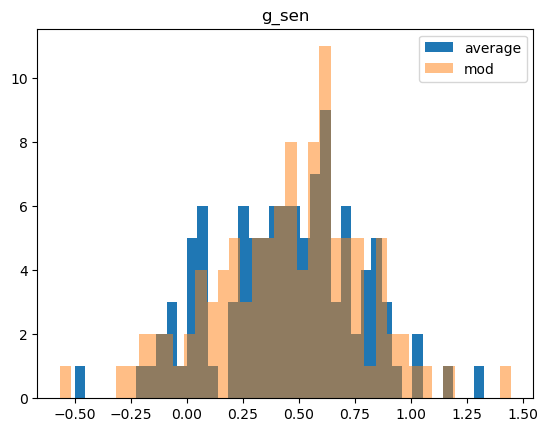

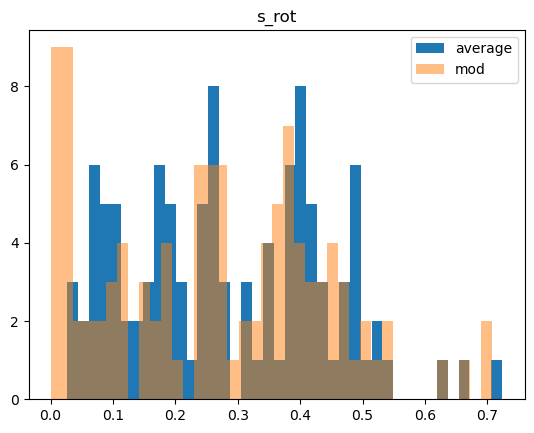

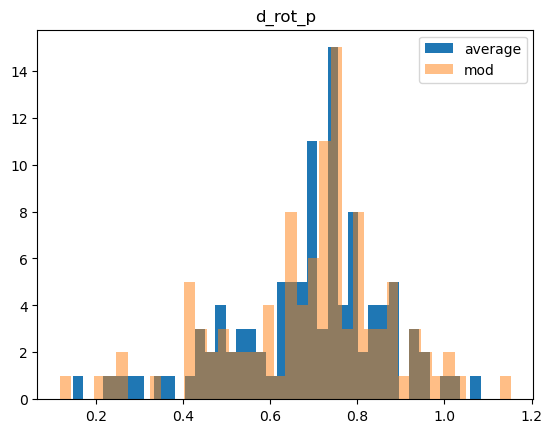

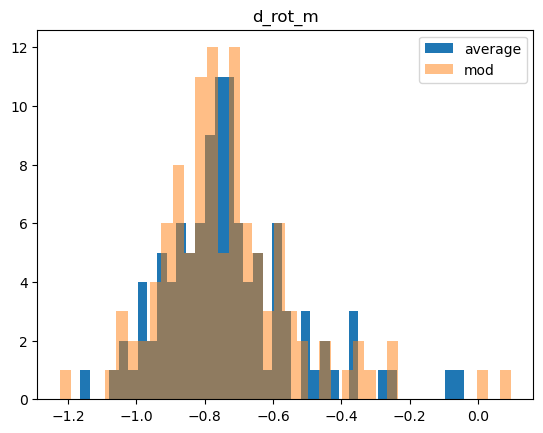

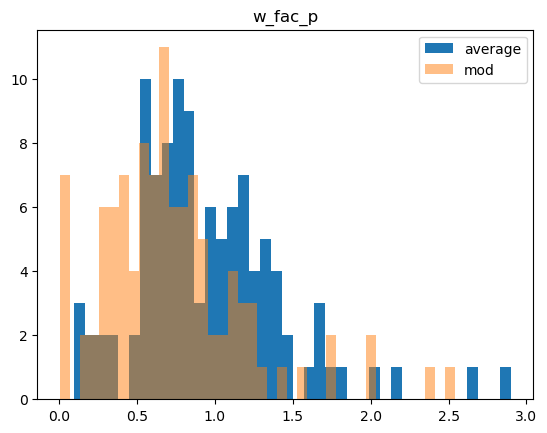

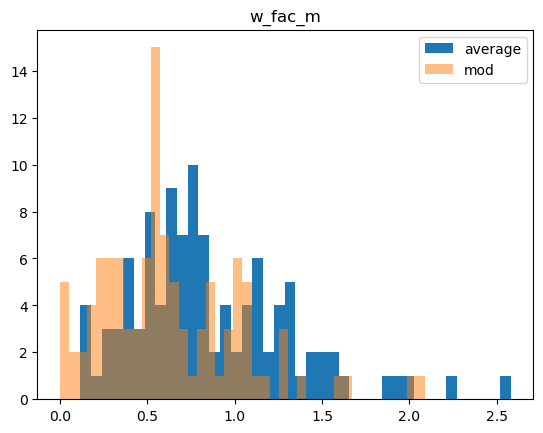

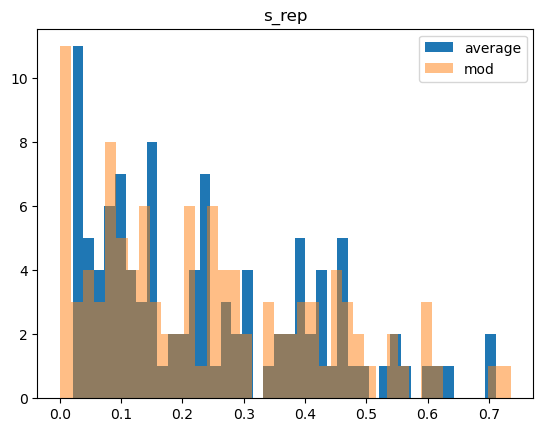

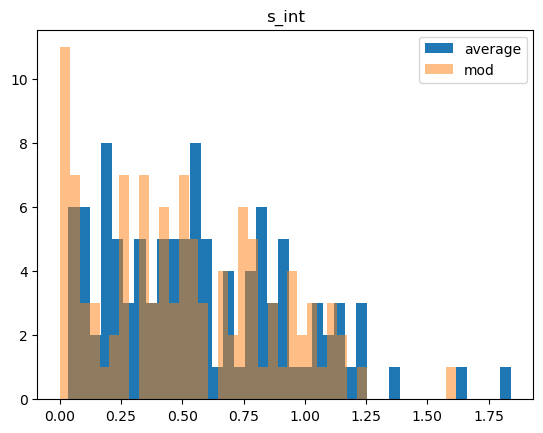

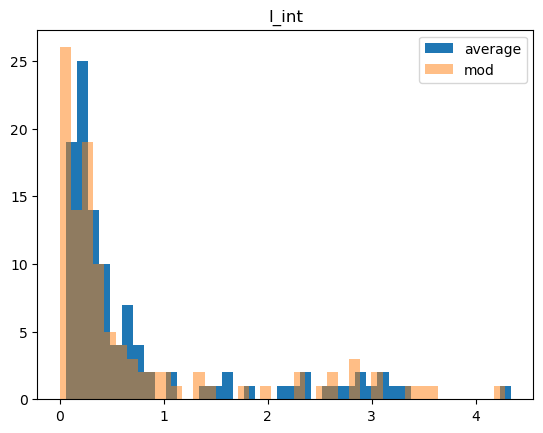

In [213]:
for name, df in fitted_params.items(): 
    plt.figure()
    plt.hist(df["average"], bins=40, label = "average")
    plt.hist(df["mod"], bins=40, alpha = 0.5, label = "mod")
    plt.title(name)
    plt.legend()
    plt.plot()